## 4. Lead-lag correlation analysis

[![content: AI-generated](../_static/badges/ai-generated.svg)](ai-acknowledgement) [![content: human-reviewed & edited](../_static/badges/human-reviewed-edited.svg)](ai-acknowledgement)

These screens use each CPI target's **quarterly change** (`cpi_qoq`, `trimmed_mean_cpi_qoq`), not the YoY series the models forecast. YoY covers overlapping four-quarter windows, so neighbouring values share three quarters of data. That makes the series very persistent and, as [§5](05_granger_causality) shows, leaves regression residuals autocorrelated, which makes Granger p-values far too small. A predictor that leads the quarterly change also leads YoY, since YoY is roughly four quarterly changes added together. Lags run from 1 to 4 quarters, and the predictor is the lagged series, so a positive lag is forecast-safe.

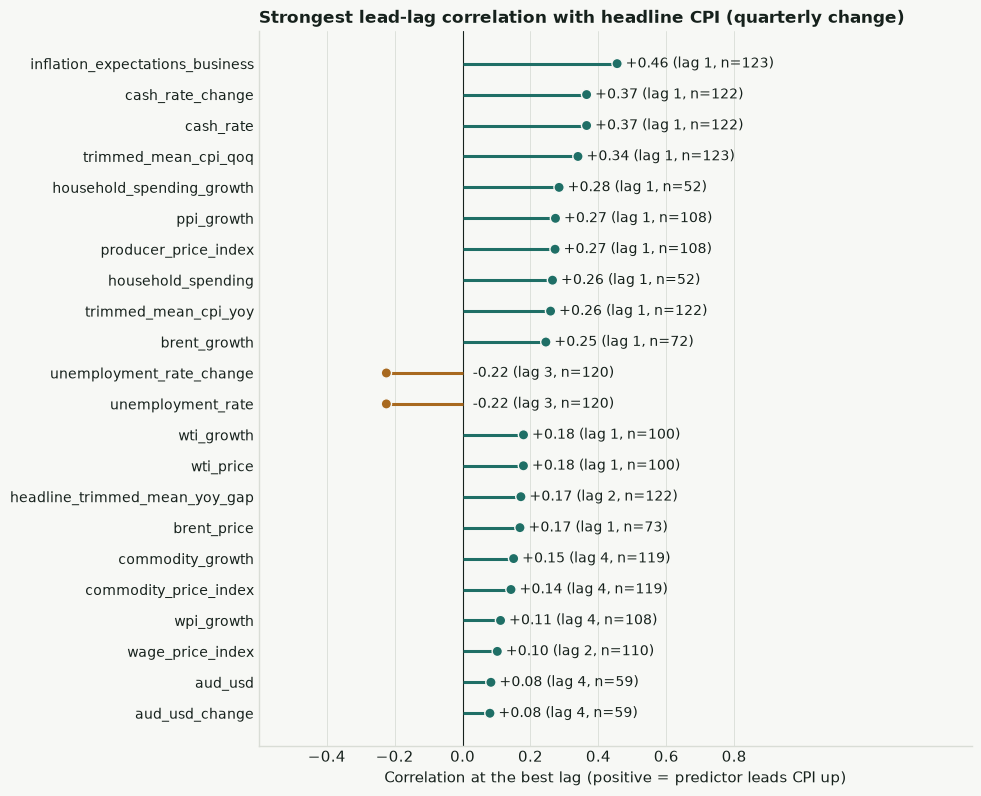

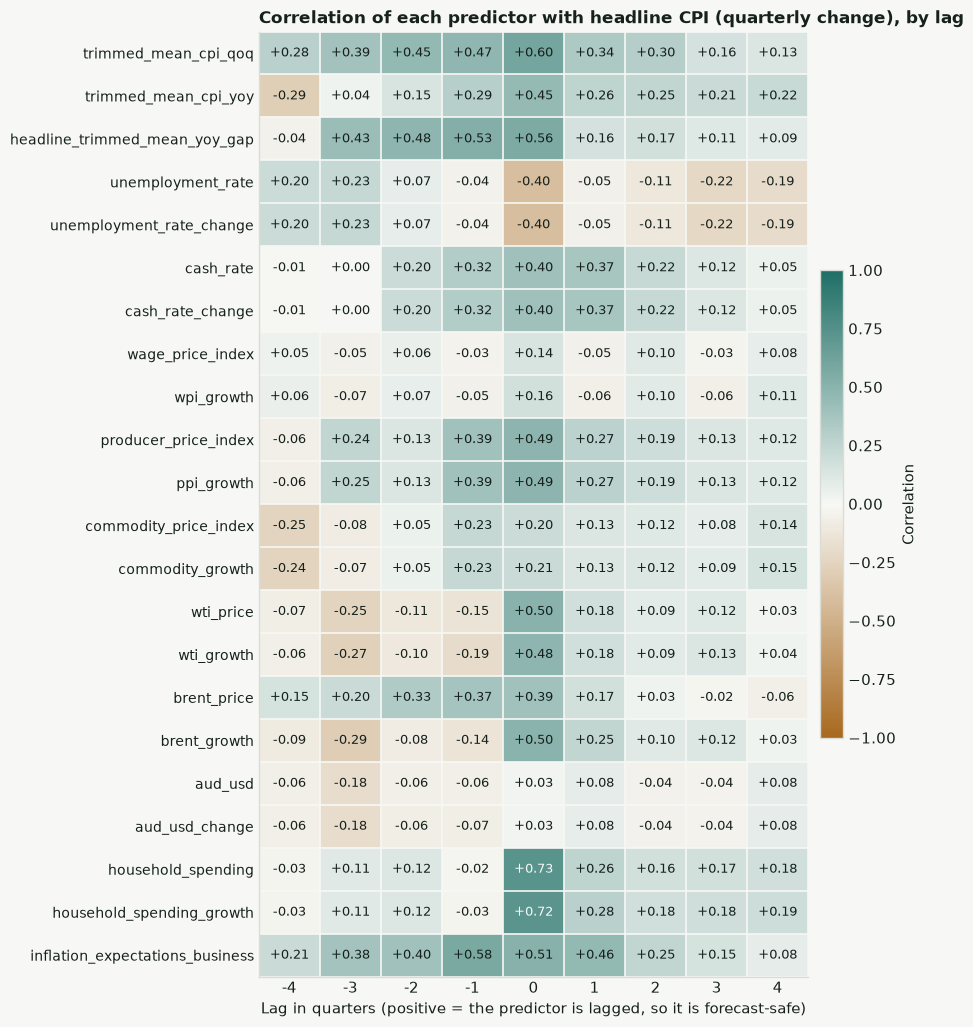

In [8]:
integration_lookup = dict(zip(stationarity['variable'], stationarity['integration_order']))

def stationary_series(column: str) -> pd.Series:
    series = clean_series(column)
    order = integration_lookup.get(column, 'unclear')
    if order == 'I(0)':
        result = series
    elif order == 'I(2)':
        result = series.diff().diff()
    else:
        log_diff = np.log(series.where(series > 0)).diff() if should_use_log_diff(column, series) else pd.Series(dtype='float64')
        result = log_diff if log_diff.notna().sum() >= 12 else series.diff()
    return result.replace([np.inf, -np.inf], np.nan).dropna()


# The screens run on each target's quarterly change. The YoY series covers overlapping four-quarter windows,
# which leaves autocorrelated regression residuals and makes Granger p-values too small.
SCREEN_TARGET = {'cpi_yoy': 'cpi_qoq', 'trimmed_mean_cpi_yoy': 'trimmed_mean_cpi_qoq'}


def screen_label(target: str) -> str:
    return TARGET_NAMES.get(target, target).replace(' YoY', '') + ' (quarterly change)'


def correlation_columns_for_target(target: str, include_cpi_diagnostics: bool) -> list[str]:
    cpi_diagnostics = [
        column for column in CPI_DIAGNOSTIC_BASE_COLS
        if include_cpi_diagnostics and column in df_model.columns and column not in (target, SCREEN_TARGET.get(target))
    ]
    return cpi_diagnostics + EXTERNAL_BASE_COLS


def compute_lead_lag_correlation(
    target: str,
    predictor_columns: list[str],
    max_lag: int = MAX_LAG,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series]:
    target_stationary_values = stationary_series(SCREEN_TARGET.get(target, target)).rename(target)
    ccf_rows = []
    for column in predictor_columns:
        x = stationary_series(column).rename(column)
        for lag in range(-max_lag, max_lag + 1):
            aligned = pd.concat([target_stationary_values, x.shift(lag)], axis=1).dropna()
            corr = aligned[target].corr(aligned[column]) if len(aligned) >= 12 else np.nan
            ccf_rows.append({
                'target': target,
                'variable': column,
                'lag_quarters': lag,
                'correlation': corr,
                'n_obs': len(aligned),
            })

    ccf_frame = pd.DataFrame(ccf_rows)
    positive_lag_ccf = ccf_frame.loc[ccf_frame['lag_quarters'] > 0].dropna(subset=['correlation']).copy()
    best_predictive = (
        positive_lag_ccf.assign(abs_correlation=lambda frame: frame['correlation'].abs())
        .sort_values(['variable', 'abs_correlation'], ascending=[True, False])
        .groupby('variable', as_index=False)
        .head(1)
        .sort_values('abs_correlation', ascending=False)
    )
    return ccf_frame, best_predictive, target_stationary_values


def display_lead_lag_correlation(
    target: str,
    predictor_columns: list[str],
    ccf_frame: pd.DataFrame,
    best_predictive: pd.DataFrame,
) -> None:
    with plt.rc_context(BOOK_STYLE):
        d = best_predictive.sort_values("abs_correlation").reset_index(drop=True)
        colour = np.where(d["correlation"] > 0, ACCENT, HIGHLIGHT)
        fig, ax = plt.subplots(figsize=(9.2, 0.34 * len(d) + 1.8))
        ax.axvline(0, color=INK, linewidth=0.8)
        ax.hlines(d.index, 0, d["correlation"], color=colour, linewidth=2.2)
        ax.scatter(d["correlation"], d.index, s=55, color=colour, edgecolor=PAPER, linewidth=1.0, zorder=3)
        for y, r in d.iterrows():
            x_text = r["correlation"] + 0.025 if r["correlation"] >= 0 else 0.03
            ax.text(x_text, y, f"{r['correlation']:+.2f} (lag {int(r['lag_quarters'])}, n={int(r['n_obs'])})",
                    va="center", ha="left", fontsize=10)
        ax.set_yticks(d.index, d["variable"], fontsize=10)
        ax.set_xlim(-0.6, 1.5)
        ax.set_xticks([-0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8])
        ax.set_xlabel("Correlation at the best lag (positive = predictor leads CPI up)")
        ax.set_title(f"Strongest lead-lag correlation with {screen_label(d['target'].iloc[0])}", loc="left",
                     fontsize=12.5, fontweight="bold")
        ax.grid(axis="y", visible=False)
        plt.show()

    heatmap_data = ccf_frame.pivot(index='variable', columns='lag_quarters', values='correlation').loc[predictor_columns]
    with plt.rc_context(BOOK_STYLE):
        fig, ax = plt.subplots(figsize=(9.4, 0.4 * len(predictor_columns) + 1.6))
        image = ax.imshow(heatmap_data, aspect='auto', cmap=DIVERGING, vmin=-1, vmax=1)
        ax.set_xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
        ax.set_yticks(range(len(heatmap_data.index)), heatmap_data.index, fontsize=10)
        for (i, j), value in np.ndenumerate(heatmap_data.to_numpy()):
            if not np.isnan(value):
                ax.text(j, i, f"{value:+.2f}", ha='center', va='center', fontsize=9.5,
                        color=PAPER if abs(value) > 0.7 else INK)
        ax.set_xticks(np.arange(-0.5, len(heatmap_data.columns)), minor=True)
        ax.set_yticks(np.arange(-0.5, len(heatmap_data.index)), minor=True)
        ax.grid(which='minor', color=PAPER, linewidth=1.2)
        ax.grid(which='major', visible=False)
        ax.tick_params(which='both', length=0)
        ax.set_xlabel('Lag in quarters (positive = the predictor is lagged, so it is forecast-safe)')
        ax.set_title(f'Correlation of each predictor with {screen_label(target)}, by lag')
        colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
        colorbar.set_label('Correlation')
        fig.tight_layout()
        plt.show()


CORRELATION_BASE_COLS = correlation_columns_for_target(TARGET, include_cpi_diagnostics=True)
ccf, best_predictive_ccf, target_stationary = compute_lead_lag_correlation(TARGET, CORRELATION_BASE_COLS)
display_lead_lag_correlation(TARGET, CORRELATION_BASE_COLS, ccf, best_predictive_ccf)

**Interpretation.** Measured on quarterly CPI, the leads are modest. Business inflation expectations one quarter earlier are the strongest (r=0.46, n=123), followed by the cash rate and its change (0.37; they're the same stationary series, so the two match). Trimmed-mean CPI's own quarterly change comes next (0.34), but it's another CPI measure rather than outside information, so it's kept out of the candidate pool (see [§5](05_granger_causality)). Household spending growth (0.28, on only 52 quarters), producer prices (0.27) and Brent growth (0.25) follow. Unemployment is the only clear negative: a rise leads lower inflation three quarters later (-0.22). Oil (WTI 0.18), wages (0.11) and AUD/USD (0.08) are close to zero.

Every predictor with a correlation of 0.24 or more peaks at lag 1. The few peaks at lag 4 (commodity prices, wages, AUD/USD) are 0.15 or smaller, too small to trust as a real lead. These best lags are descriptive only: the lag used for each candidate feature comes from the BIC choice in [§5](05_granger_causality), not from the tallest bar here. The correlations are also smaller than the 0.5 to 0.7 the YoY version of this chart showed for the top predictors. Two slow-moving YoY series drift together by construction, so those bigger numbers probably reflect the overlap and not extra predictive information.

In [ ]:
# Guard: every figure quoted in the interpretation above.
b = best_predictive_ccf.set_index('variable')
for name, lag, r, n in [
    ('inflation_expectations_business', 1, 0.46, 123), ('cash_rate', 1, 0.37, 122), ('cash_rate_change', 1, 0.37, 122),
    ('trimmed_mean_cpi_qoq', 1, 0.34, 123), ('household_spending_growth', 1, 0.28, 52), ('ppi_growth', 1, 0.27, 108),
    ('producer_price_index', 1, 0.27, 108), ('brent_growth', 1, 0.25, 72), ('unemployment_rate', 3, -0.22, 120),
    ('wti_growth', 1, 0.18, 100), ('wpi_growth', 4, 0.11, 108), ('aud_usd', 4, 0.08, 59),
]:
    assert (int(b.loc[name, 'lag_quarters']), round(b.loc[name, 'correlation'], 2), int(b.loc[name, 'n_obs'])) == (lag, r, n), name
assert (b.loc[b['correlation'].abs() >= 0.24, 'lag_quarters'] == 1).all()
lag4 = b.loc[b['lag_quarters'] == 4]
assert {'commodity_growth', 'commodity_price_index', 'wpi_growth', 'aud_usd', 'aud_usd_change'} <= set(lag4.index)
assert round(lag4['correlation'].abs().max(), 2) <= 0.15